## Live prototype

Open https://empathmaps.netlify.app/app.html to select any of 19 categories, including gyms, recreation centers, pools, banks, parks and schools. The current catalog contains 390 candidates. Equation: https://empathmaps.netlify.app/method.html .

# Network-derived walking accessibility

## 1. Weighted paths → closest services → block score

$$w_e=\frac{L_e}{1.2}\left[1+\frac{(1-\widehat C_e)+\widehat Q_e+\widehat H_e}{3}\right]$$

Edge cost is ordinary walking time multiplied by an estimated environmental penalty. Block-context canopy, traffic and surface-temperature proxies are used; equal factor weights are assumptions.

$$C_k(b)=\min_{d\in D_k}\sum_{e\in P(b,d)}w_e,\qquad A(b)=\frac{1}{K}\sum_{k=1}^{K}C_k(b)$$

For each category, find the lowest-cost path from the block's snapped reference node to any suitable catalog destination. Then average the category costs. We also export their sum and the worst trip.

**This counts one closest candidate per category, not every business.** The activity graph has no block–block or POI–POI edges.

## 2. Colors
- Weighted path colors now use the pilot's 2nd–98th percentile range: **blue = lower relative friction; red = higher**. Actual weights are unchanged.
- Block colors independently stretch aggregated accessibility costs to 0–100, with the same blue–red meaning.
- Blue means relatively better, not friction-free or medically safe.
- If any selected category is unreachable, the overall block score stays unknown (gray).


weighted_edges            93450
excluded_unknown_edges        2
blocks                     2862
pois                        390
temple_candidates             5
Name: Count, dtype: int64

Blocks with complete all-category scores: 2804


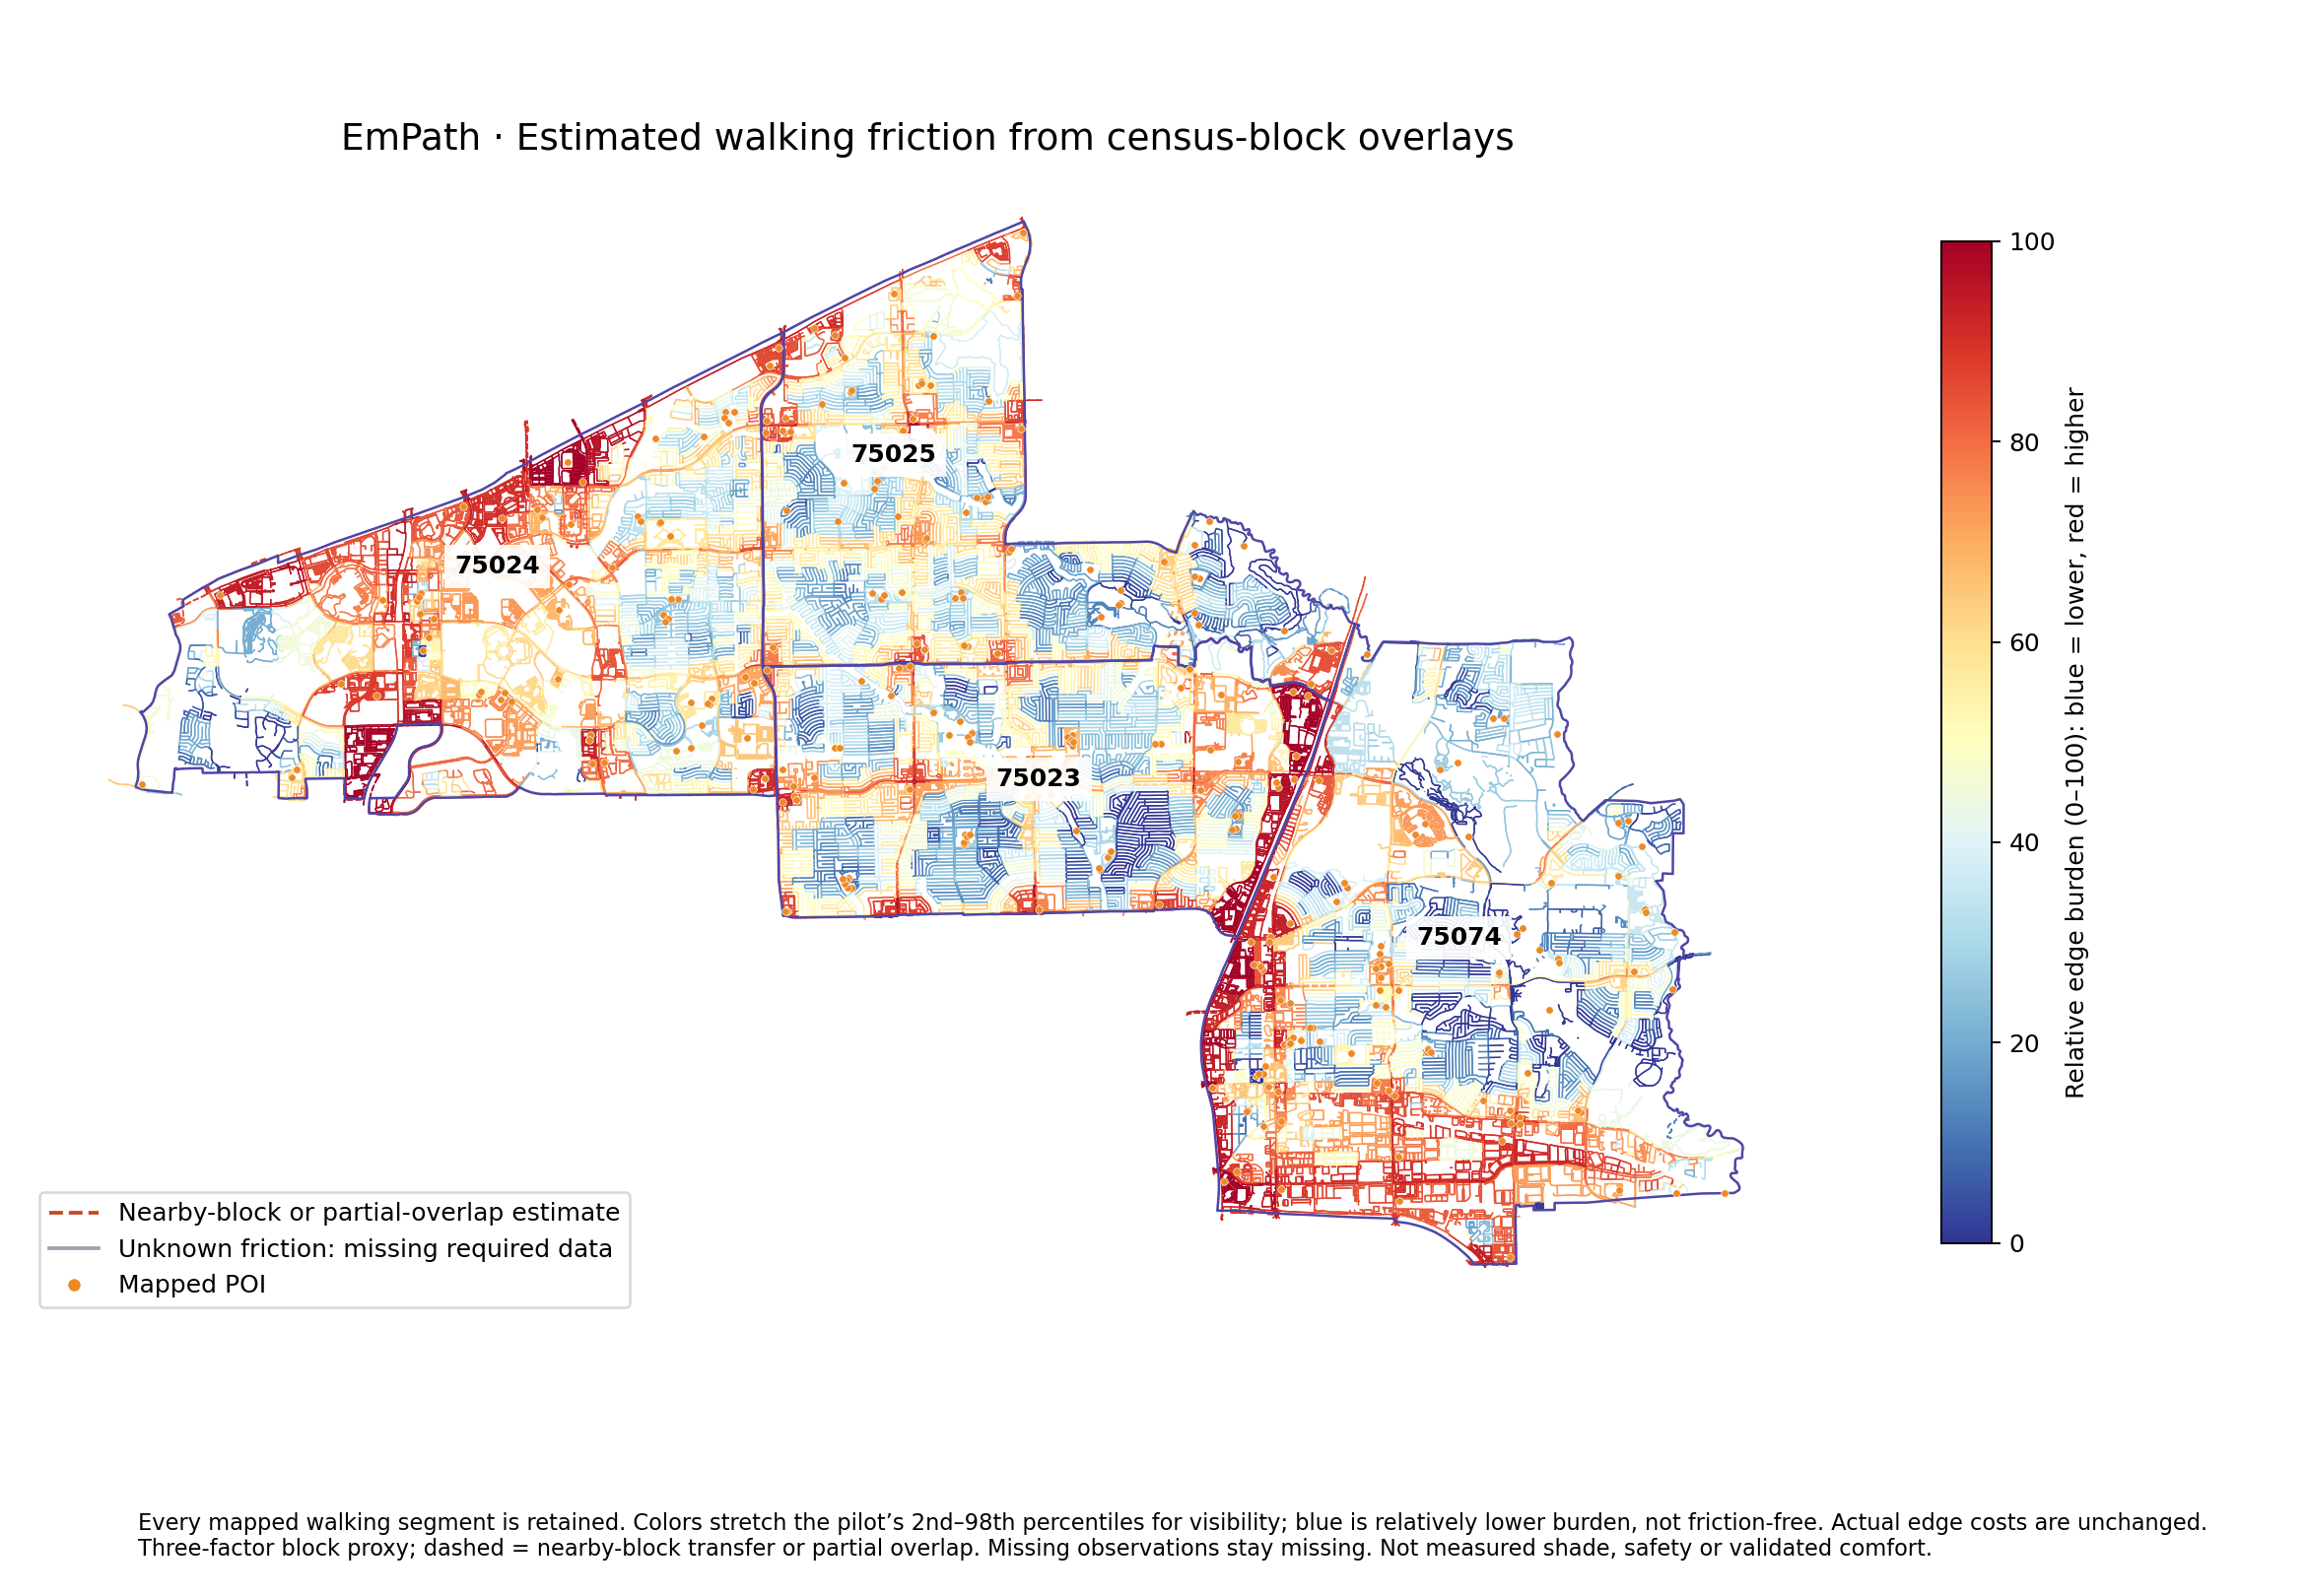

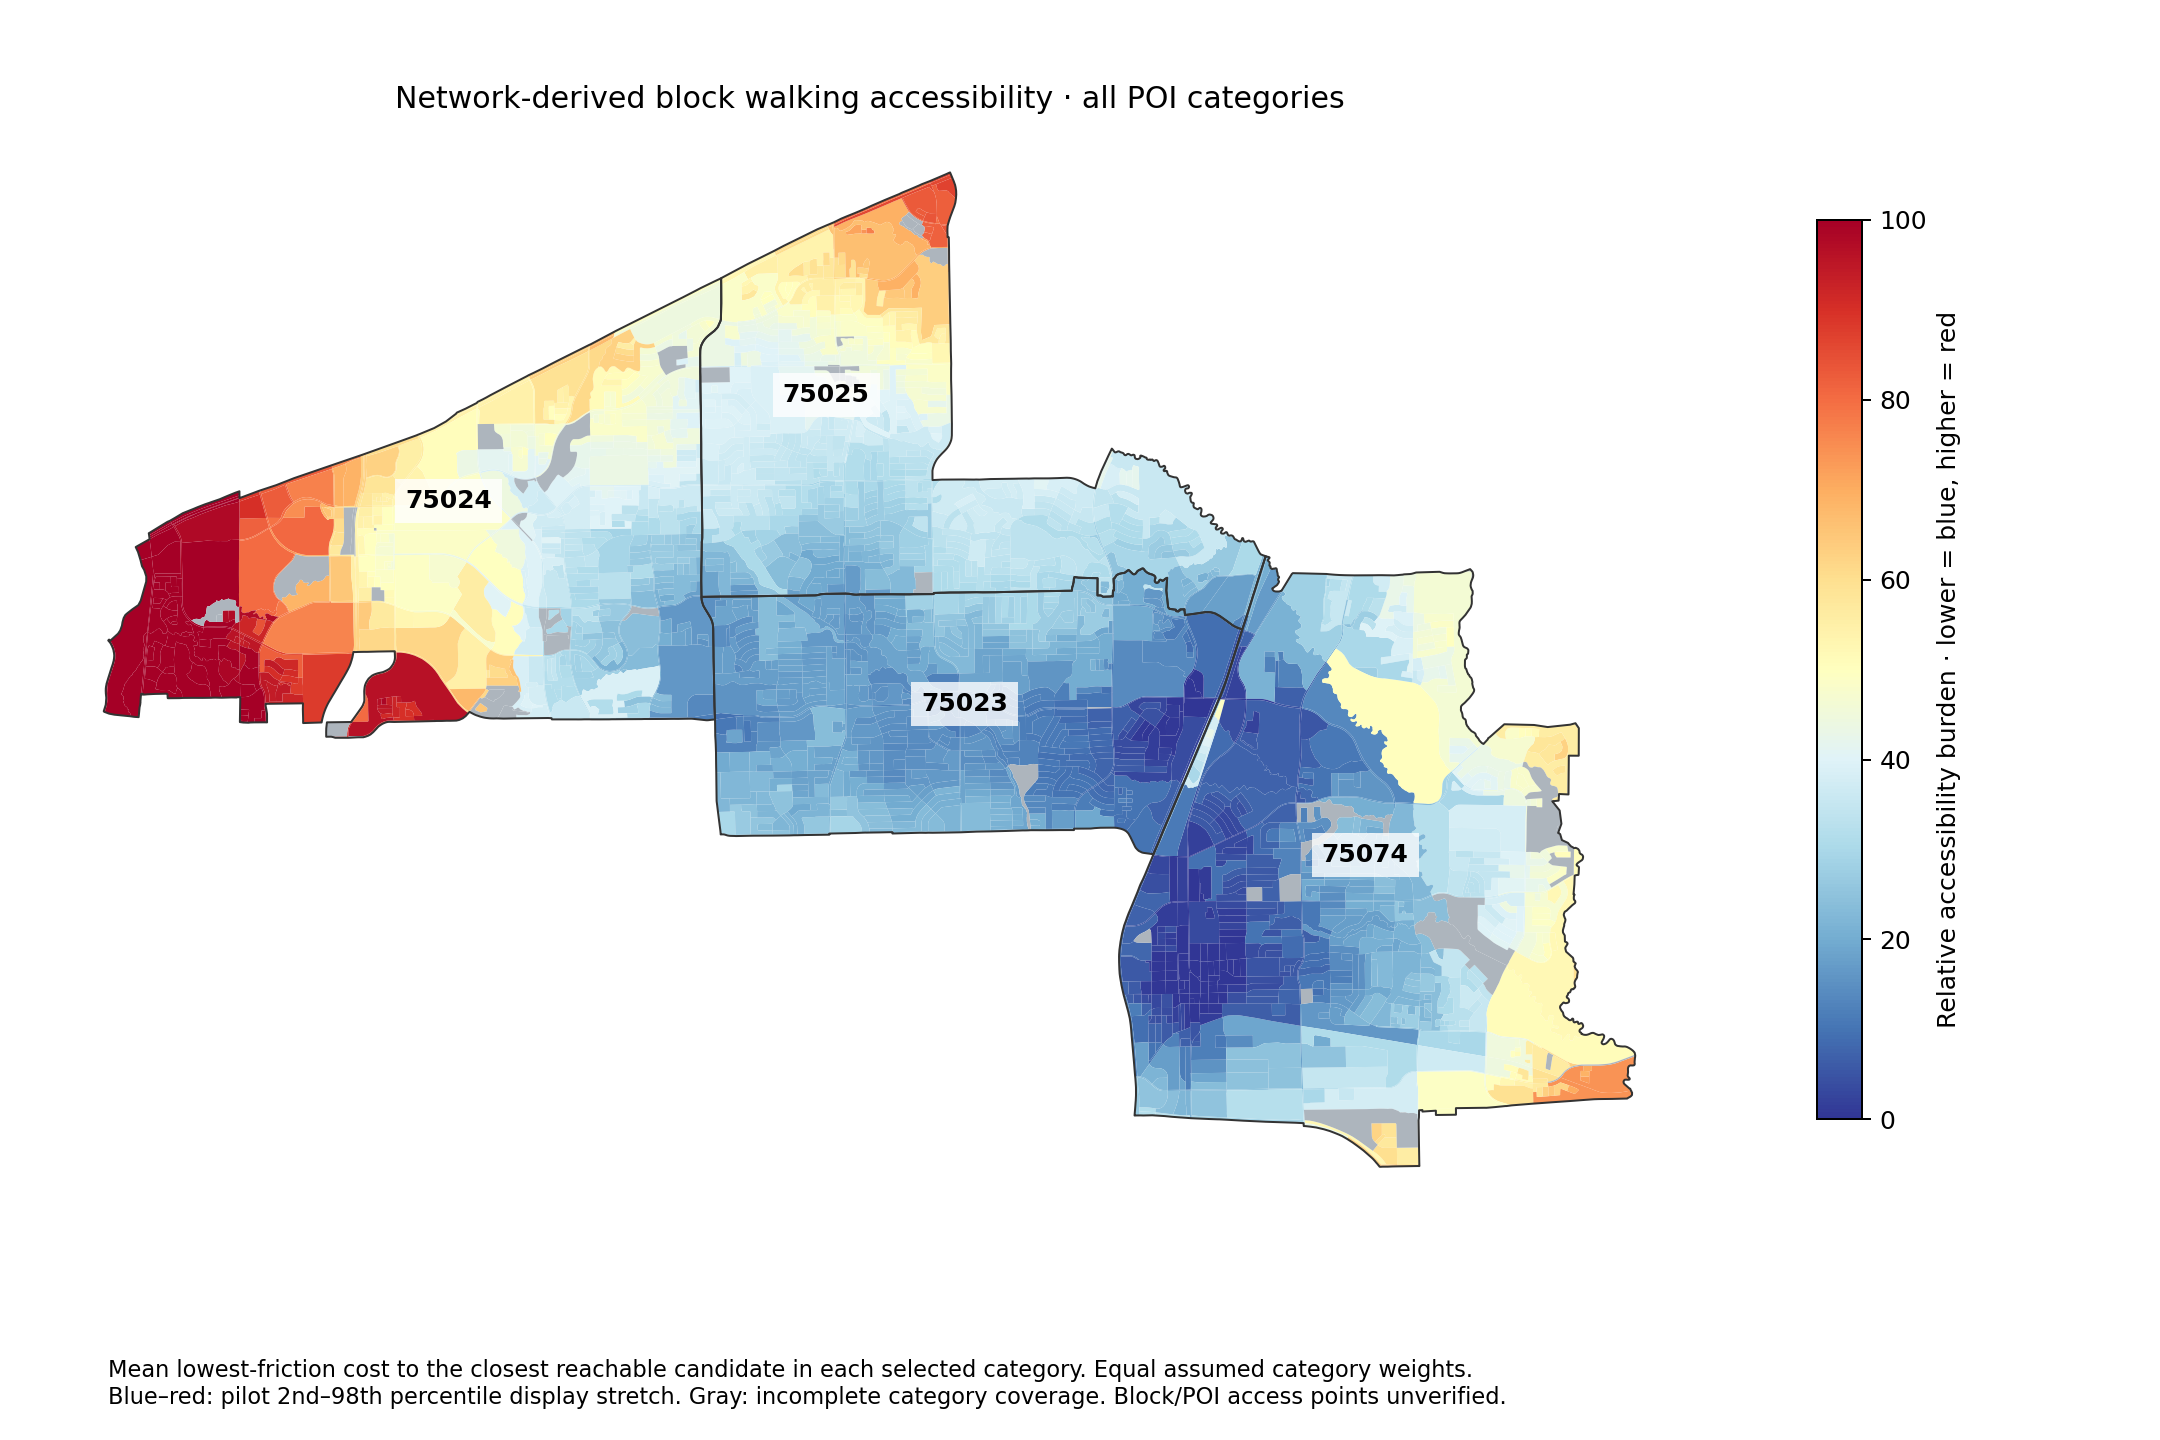

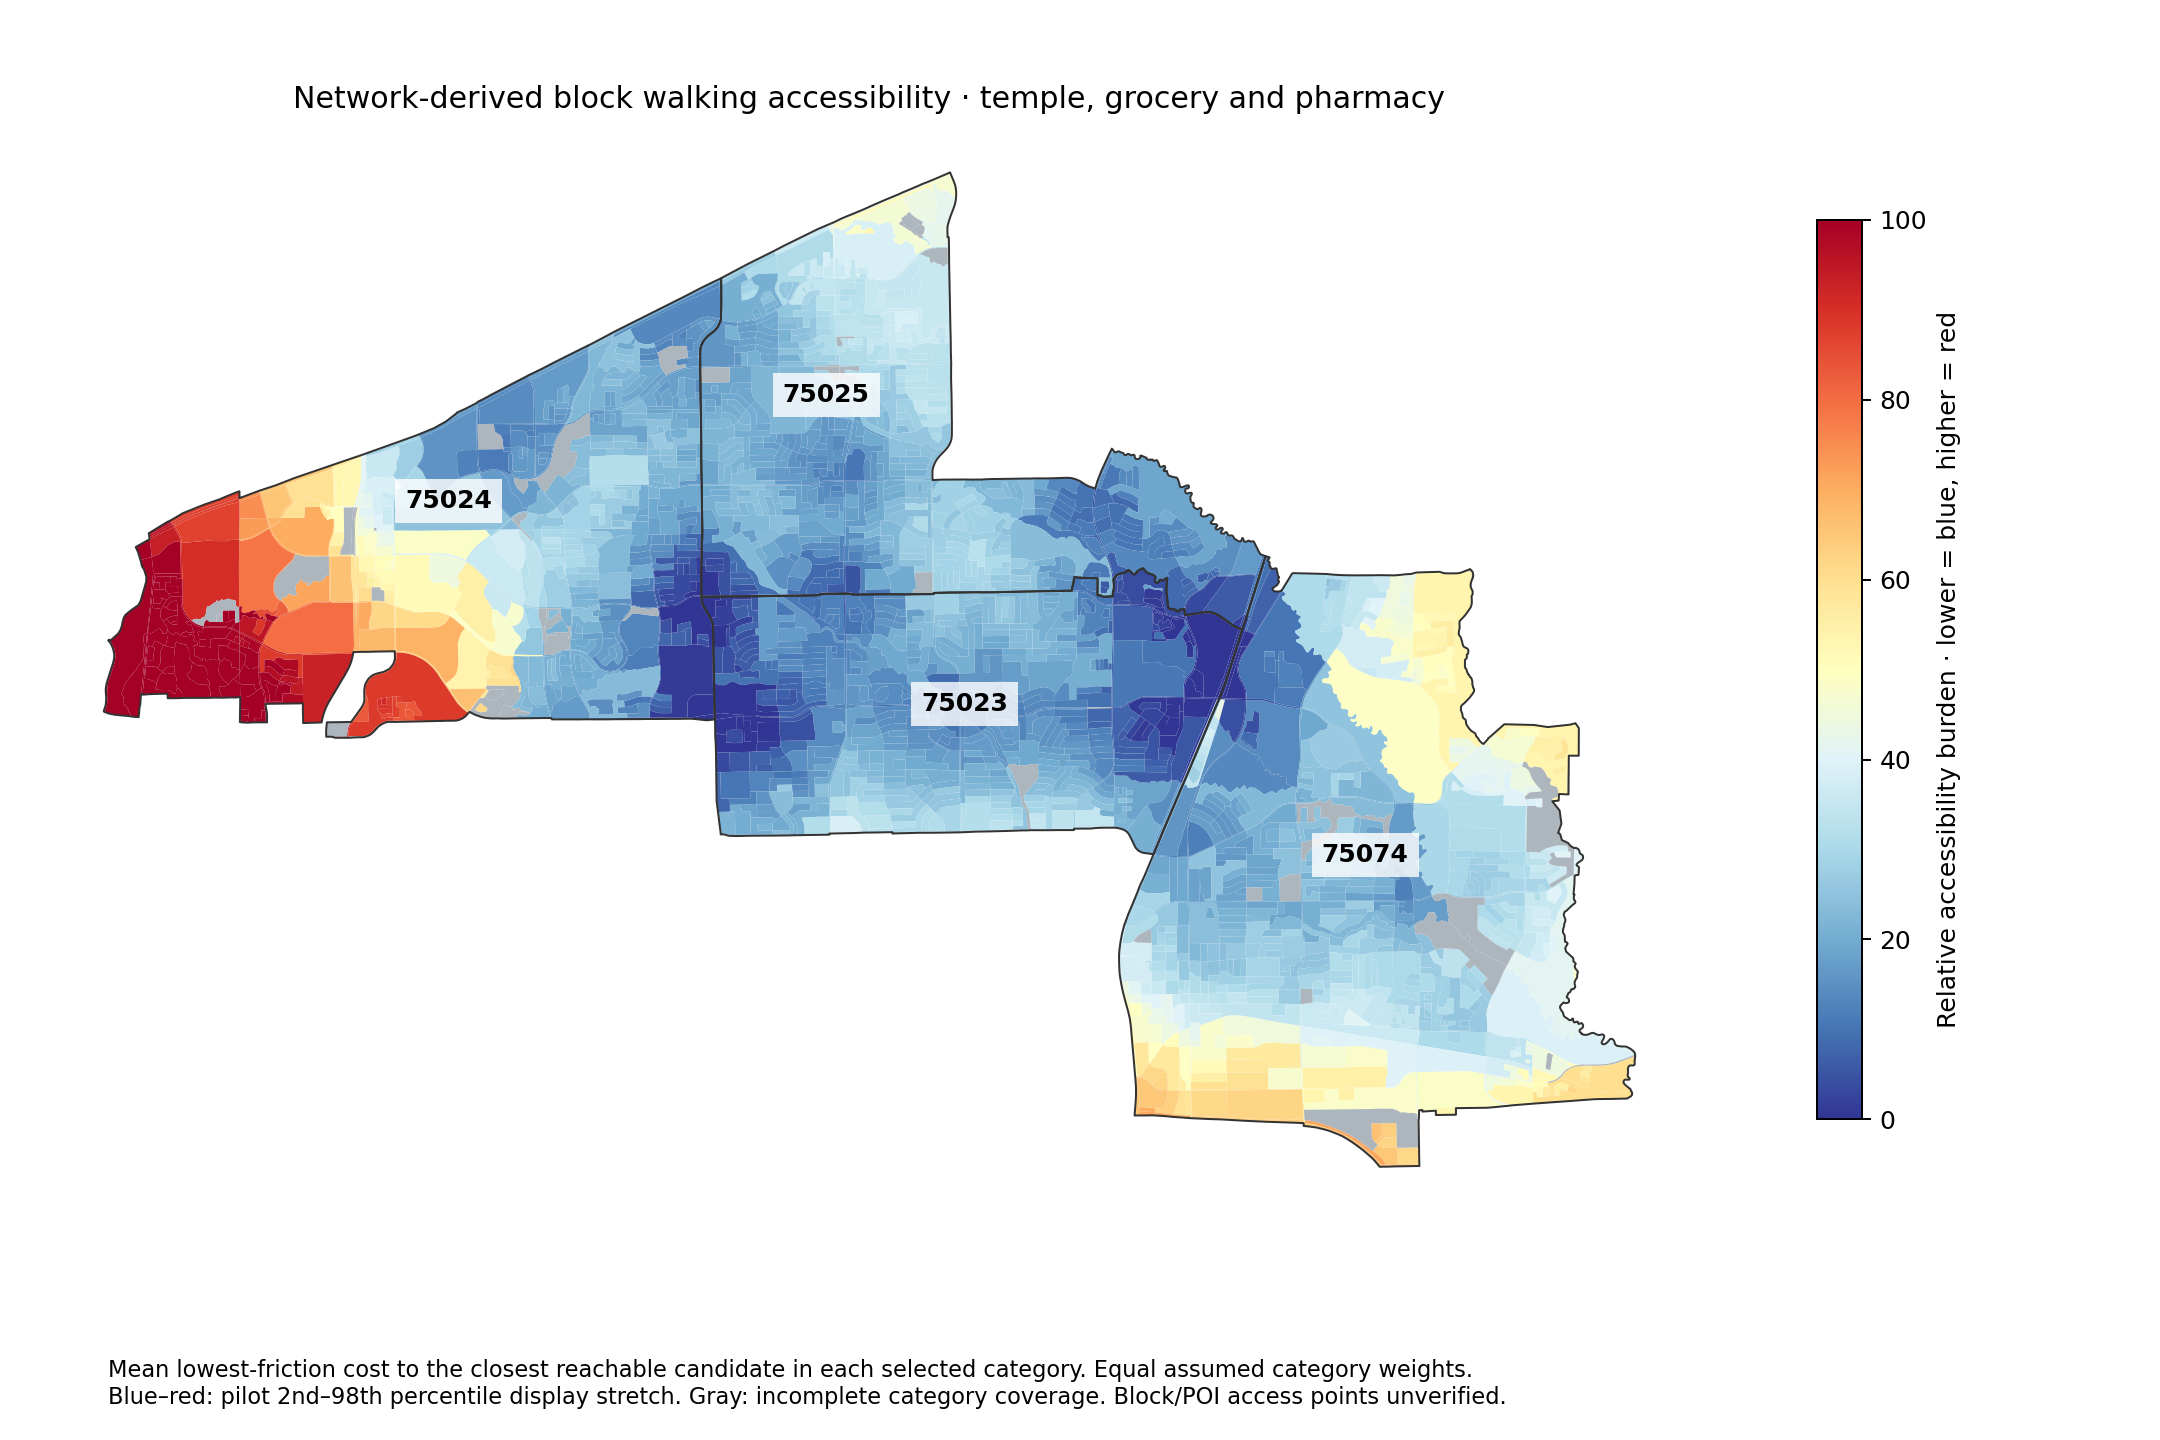

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, FileLink
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
REBUILD=False
if REBUILD:
    from visualize_weighted_walking_network import run as draw_network
    from score_block_accessibility import run as score_blocks
    from map_block_accessibility import run as draw_blocks
    draw_network()
    score_blocks()
    draw_blocks()
OUT=ROOT/'output/block_accessibility'
method=json.loads((OUT/'accessibility_method.json').read_text())
blocks=pd.read_csv(OUT/'block_accessibility.csv',dtype={'GEOID20':str})
display(pd.Series({key:method[key] for key in ['weighted_edges','excluded_unknown_edges','blocks','pois','temple_candidates']},name='Count'))
print('Blocks with complete all-category scores:',blocks.access_all_categories_burden_0_100.notna().sum())
display(Image(filename=str(ROOT/'output/weighted_walking_network/block_proxy_weighted_network.png')))
display(Image(filename=str(OUT/'block_accessibility_all_categories.png')))
display(Image(filename=str(OUT/'block_accessibility_essential.png')))


## 3. Open the interactive maps

- `output/weighted_walking_network/block_proxy_weighted_network.html`: full weighted walking graph, normalized blue–red colors and Rowlett Creek locator.
- `output/block_accessibility/block_accessibility_map.html`: new network-derived choropleth. Choose all categories or temple–grocery–pharmacy; click blocks for nearest destinations and costs.
- `output/clean_deliverables/all_layers_map.html`: original environmental layers with the new network-derived score replacing the old provisional layer as the default accessibility layer.

**Graphs:** `weighted_walking_graph.graphml.gz` contains finite edge weights; `block_nearest_category_activity_graph.graphml` contains weighted block nodes and one closest-POI recommendation per category. Both are in `output/block_accessibility/`.


In [2]:
nearest=pd.read_csv(OUT/'nearest_category_costs.csv',dtype={'GEOID20':str})
block_id=blocks.loc[blocks.access_all_categories_burden_0_100.notna(),'GEOID20'].iloc[0]
display(nearest[nearest.GEOID20.eq(block_id)][['category','closest_poi_name','min_friction_equivalent_minutes','origin_snap_gap_m','destination_snap_gap_m']])
for p in [OUT/'block_accessibility_map.html',ROOT/'output/weighted_walking_network/block_proxy_weighted_network.html']:
    print(p)
    display(FileLink(str(p)))


,category,closest_poi_name,min_friction_equivalent_minutes,origin_snap_gap_m,destination_snap_gap_m
0,bank,Capital One,67.534981,85.200131,23.096137
2862,bus_station,Parker Road Station,143.684767,85.200131,16.397371
5724,clinic,Baylor Scott & White Urgent Care,153.805581,85.200131,23.931905
8586,college,Collin College - Spring Creek Campus,76.393814,85.200131,34.829424
11448,community_centre,Plano Masonic Lodge,180.042642,85.200131,15.638897
14310,convenience,RaceTrac,58.398539,85.200131,34.714041
17172,gym,LA Fitness,63.496337,85.200131,45.184807
20034,hindu_temple,Sri Ganesha Temple,51.105126,85.200131,34.827951
22896,hospital,Eating Recovery Center Dallas / Plano,314.484295,85.200131,30.514056
25758,library,Collin College Spring Creek Campus Library,85.796998,85.200131,69.389716


/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/block_accessibility/block_accessibility_map.html


/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/block_accessibility/block_accessibility_map.html

/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/block_proxy_weighted_network.html


/Users/nalinikantheti/Documents/ChatGPT/EmPath/output/weighted_walking_network/block_proxy_weighted_network.html

## 4. Read the limits before presenting

- 2,804 of 2,862 blocks reach a candidate in every selected category; 58 are incomplete.
- Every block is a geographic reference origin, including parks and other nonresidential land. This is not a ranking of verified homes for sale.
- Block reference points and destinations snap to nearest junctions. Large gaps are flagged. Entrances, connectors and crossings remain unverified; connector travel and crossing waits are omitted.
- POIs are limited to the pilot scope, so services just outside the boundary are omitted. Destination completeness can affect rankings.
- The original OSM query omitted worship. Five Hindu-temple address candidates were added from `config/accessibility_temples.json` using municipal address-point coordinates. Raghunath's street address is directory-sourced and needs review. Address points are not entrances; the catalog is not exhaustive.
- All-category scoring equally weights 19 categories, including categories such as college and playground. Use the essential profile for temple, supermarket and pharmacy; equal weights represent a prototype choice, not universal needs.
- GeoAI supplied the earlier tree predictions. Network routing, spatial proxies and aggregation are conventional analysis, not newly trained preference models.
- Website source assets are updated locally; no live deployment is claimed.
